# 0. Setup

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [33]:
data_path = '../data/raw/all_reviews 2.csv'

df = pd.read_csv(data_path)

/var/folders/7v/lvj2kzs55lvfyy7wg051wp2m0000gn/T/ipykernel_32826/1210821541.py:3: DtypeWarning: Columns (5: advice, 9: Career Opportunities, 10: Compensation and Benefits, 11: Senior Management, 12: Work/Life Balance) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path)


In [34]:
df.shape

(9901889, 19)

In [35]:
# For visalization 1
df.head(5)

,rating,title,status,pros,cons,advice,Recommend,CEO Approval,Business Outlook,Career Opportunities,Compensation and Benefits,Senior Management,Work/Life Balance,Culture & Values,Diversity & Inclusion,firm_link,date,job,index
0,5.0,Good,"Current Employee, more than 10 years",Knowledge gain of complete project,Financial growth and personal growth,NaN,v,o,v,3,3,3,3,3.0,3.0,Reviews/Baja-Steel-and-Fence-Reviews-E5462645.htm,"Nov 19, 2022",Manager Design,NaN
1,4.0,Good,"Former Employee, less than 1 year","Good work,good work , flexible, support","Good,work, flexible,good support, good team work",NaN,v,o,o,4,4,4,4,4.0,4.0,Reviews/Baja-Steel-and-Fence-Reviews-E5462645.htm,"Jan 29, 2022",Anonymous Employee,NaN
2,4.0,"Supervising the manufacturing the processes, e...","Current Employee, more than 1 year",This company is a best opportunity for me to l...,"Monthly Target work,Maintain production schedu...",NaN,v,o,v,2,3,2,2,2.0,2.0,Reviews/Baja-Steel-and-Fence-Reviews-E5462645.htm,"Aug 12, 2021",Production Engineer,NaN
3,1.0,terrible,"Current Employee, more than 1 year",I wish there were some to list,too many to list here,NaN,x,x,x,1.0,3.0,1.0,3.0,1.0,NaN,https://www.glassdoor.com/Reviews/Calgary-Flam...,"Sep 24, 2020",Senior Account Executive,NaN
4,4.0,"It could be so good, but it isn’t","Current Employee, more than 3 years",Fast Paced. Endless challenges. Inclusive envi...,The biggest perk of the job provides no value ...,NaN,o,o,o,3.0,3.0,3.0,1.0,4.0,5.0,https://www.glassdoor.com/Reviews/Calgary-Flam...,"Mar 25, 2023",Assistant Manager,NaN


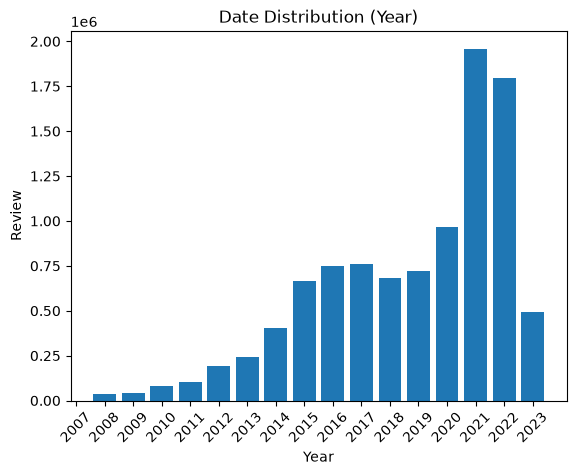

In [36]:
copied_df = df.copy()
copied_df["date"] = pd.to_datetime(copied_df["date"])

plt.hist(copied_df["date"].dt.year, bins=np.arange(2007.5, 2024.5, 1), rwidth=0.8)
plt.title("Date Distribution (Year)")
plt.ylabel("Review")
plt.xlabel("Year")
plt.xticks(range(2007, 2024), rotation=45)

plt.show()

In [37]:
status = copied_df["status"].str.strip()
copied_df["emp_type"] = status.str.extract(r"^(?:Current|Former) ([^,]+)")[0]

print(copied_df["emp_type"].unique())
print(f"Employee: {(len(copied_df[copied_df["emp_type"] == 'Employee']) / len(copied_df["emp_type"])) * 100} %")

<ArrowStringArray>
[          'Employee',         'Contractor', 'Temporary Employee',
             'Intern',         'Freelancer',                  nan,
         'Apprentice',            'Trainee',                'PhD']
Length: 9, dtype: str
Employee: 99.89916065510329 %


# 1. Data Cleaning

In [38]:
columns = ["title", "rating", "status", "pros", "cons", "firm_link", "date", "job"]
df = df[columns]

In [39]:
df.head(1)

,title,rating,status,pros,cons,firm_link,date,job
0,Good,5.0,"Current Employee, more than 10 years",Knowledge gain of complete project,Financial growth and personal growth,Reviews/Baja-Steel-and-Fence-Reviews-E5462645.htm,"Nov 19, 2022",Manager Design


In [40]:
df["firm_id"] = df["firm_link"].str.extract(r"-Reviews-E(\d+)")[0]
df["number of reviews"] = df["firm_id"].map(df["firm_id"].value_counts())
print(df["number of reviews"].describe())
print(f"Number of firms: {df['firm_id'].nunique()}")
print(f"Missing firm_id: {df['firm_id'].isna().sum()}")

count    9.901889e+06
mean     1.423114e+04
std      2.547091e+04
min      1.000000e+00
25%      1.275000e+03
50%      4.390000e+03
75%      1.353400e+04
max      1.584920e+05
Name: number of reviews, dtype: float64
Number of firms: 35311
Missing firm_id: 0


In [41]:
# Drop duplicates
key = ["title", "rating", "status", "pros", "cons", "firm_id", "date", "job"]
n_before = len(df)
df = df.drop_duplicates(subset=key)
print(f"Before: {n_before}\nAfter: {len(df)}")

Before: 9901889
After: 9466241


In [42]:
# Create new columns from status, date, and rating
df = df.drop(columns="pros")

status = df["status"].str.strip()
df["former"] = status.str.extract(r"^(Current|Former) ")[0].map({"Current": 0, "Former": 1})
df["emp_type"] = status.str.extract(r"^(?:Current|Former) ([^,]+)")[0]
df["tenure"] = status.str.extract(r"(less than 1 year|more than \d+ years?)")[0]
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["year"] = df["date"].dt.year
df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

In [43]:
# Drop invalid rows
n_before = len(df)
df = df.dropna(subset=["firm_id", "rating", "former", "date"])
print(f"Before: {n_before:,}\nAfter: {len(df):,}")

df = df.astype({"firm_id": "int64", "rating": "int8", "former": "int8", "year": "int16"})
df["emp_type"] = df["emp_type"].astype("category")
df["tenure"] = df["tenure"].astype("category")
df["number of reviews"] = df["firm_id"].map(df["firm_id"].value_counts())

print(df["rating"].value_counts().sort_index())
print(df["former"].value_counts())
print(df["emp_type"].value_counts().head(10))

Before: 9,466,241
After: 9,465,873
rating
1     891219
2     983161
3    2193082
4    2826220
5    2572191
Name: count, dtype: int64
former
0    5457688
1    4008185
Name: count, dtype: int64
emp_type
Employee              9456305
Intern                   4246
Contractor               3957
Freelancer                887
Temporary Employee        470
Apprentice                  6
PhD                         1
Trainee                     1
Name: count, dtype: int64


In [44]:
cols = ["firm_id", "rating", "former", "emp_type", "tenure", "year", "date", "number of reviews", "cons", "job"]
df = df[cols]

In [45]:
# Targets are only employees
# And use reviews since 2020
n_before = len(df)
df = df[(df["emp_type"] == "Employee") & (df["year"] >= 2020)]
df["number of reviews"] = df["firm_id"].map(df["firm_id"].value_counts())
print(f"Before: {n_before:,}\nAfter: {len(df):,}")

Before: 9,465,873
After: 4,950,344


In [46]:
# Save
processed_path = '../data/processed/processed.parquet'
df.to_parquet(processed_path, index=False)